# Missed GP Appointments in England
### What makes patients more likely to miss a GP appointment?

**Question:** Which appointment characteristics are associated with a higher rate of missed ("did not attend", DNA) GP appointments, how has this changed over time, and which areas have more missed appointments than expected?

**Data:** NHS England, *Appointments in General Practice*, daily counts by Sub-ICB location, August 2020 – September 2026. Contains public sector information licensed under the Open Government Licence v3.0.

**Design:** Cross-sectional and trend analysis of routinely collected administrative health service data.

**Author:** Marina Gorikova

In [243]:
# ==============================================================
# Imports and style for all figures and tables
# ==============================================================
import os, glob, re, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint
from IPython.display import display

# ---- Figures ----
plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.labelcolor": "black",
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.titlepad": 30,
    "axes.titlelocation": "left",
    "figure.titlesize": 16,
    "figure.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

# ---- Tables ----
CAPTION_STYLE = [{"selector": "caption",
                  "props": "font-size: 16px; font-weight: bold; color: black; "
                           "text-align: left; padding-top: 30px; padding-bottom: 8px;"}]

from IPython.display import HTML

def show_table(table, title, formats=None, bold_cols=None):
    """Display a bold title (with space above it), then the table.
    Uses <br> and <b> tags so it also looks right on GitHub."""
    formats = dict(formats or {})
    bold_cols = bold_cols or []

    def make_format(col):
        f = formats.get(col)
        def fmt(v):
            if f:
                s = f.format(v)
            elif isinstance(v, float):
                s = f"{v:.4f}"
            else:
                s = str(v)
            return f"<b>{s}</b>" if col in bold_cols else s
        return fmt

    styled = table.style.format({c: make_format(c) for c in table.columns})

    if title:
        display(HTML(f'<div style="font-size:21px; font-weight:bold; color:black; '
                     f'margin-top:10px; margin-bottom:4px">{title}</div>'))   # space + bold title above the table
    display(styled)

## Step 1. Combine the monthly files

The data comes as one CSV file per monthly NHS release. Some releases repeat earlier dates, and later releases can **revise** earlier counts, so simply stacking the files would count some appointments twice.

Rules used:
1. **Skip repeated files:** files with the same name in two folders, or identical contents, are used once.
2. **Skip files with an unexpected name** (no month and year, e.g. summaries).
3. **Keep each date once:** if a date appears in several files, keep it from the **newest** release only, because it contains the most up-to-date counts.

Checks after combining: no missing dates, and no area/date/category combination appears more than once.

In [244]:
# ==============================================================
# Combine all monthly files, skipping repeated files and repeated dates
# (run once only: the result is saved as data_combined.csv.gz)
# ==============================================================
COUNT_COL = "COUNT_OF_APPOINTMENTS"
OUT_FILE = "data_combined.csv.gz"

def file_date(path):
    """'..._Oct_21.csv' -> 1 Oct 2021. Returns None if the name has no month_year."""
    m = re.search(r"([A-Za-z]{3})_(\d{2})(?:\D*)\.csv$", os.path.basename(path))
    if not m:
        return None
    try:
        return pd.to_datetime(f"01 {m.group(1)} 20{m.group(2)}", format="%d %b %Y")
    except ValueError:
        return None

def file_hash(path):
    """Fingerprint of a file's contents, to spot identical copies."""
    h = hashlib.md5()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()

def text_to_category(table):
    """Store text columns as categories (saves a lot of memory)."""
    for c in table.columns:
        if pd.api.types.is_string_dtype(table[c]):
            table[c] = table[c].astype("category")
    return table

# --- Stage 1: skip repeated files --------------------------------
found = glob.glob("data/**/*.csv", recursive=True)
skipped = [(f, "name has no month_year") for f in found if file_date(f) is None]
all_files = sorted([f for f in found if file_date(f) is not None], key=file_date)

files, seen_names, seen_hashes = [], {}, {}
for f in all_files:
    name = os.path.basename(f)
    if name in seen_names:
        skipped.append((f, f"same name as {seen_names[name]}"))
        continue
    key = (os.path.getsize(f), file_hash(f))
    if key in seen_hashes:
        skipped.append((f, f"identical to {seen_hashes[key]}"))
        continue
    seen_names[name], seen_hashes[key] = f, f
    files.append(f)
skipped = pd.DataFrame(skipped, columns=["file", "reason"])

# Find the date column automatically (e.g. 'Appointment_Date')
DATE_COL = next(c for c in pd.read_csv(files[0], nrows=0).columns if "date" in c.lower())

# --- Stage 2a: which dates does each file contain? -----------------
# Files are in date order, so a newer file overwrites an older one
date_owner = {}
for f in files:
    for d in pd.read_csv(f, usecols=[DATE_COL])[DATE_COL].unique():
        date_owner[d] = f

# --- Stage 2b: read each file, keep only the dates it "owns" -------
parts, report = [], []
for f in files:
    df = pd.read_csv(f, low_memory=False)
    keep = df[DATE_COL].map(date_owner) == f
    parts.append(text_to_category(df[keep].copy()))
    report.append([os.path.basename(f), int(keep.sum()), int((~keep).sum())])

combined = text_to_category(pd.concat(parts, ignore_index=True))
report = pd.DataFrame(report, columns=["file", "rows_kept", "rows_skipped_repeated_dates"])

# --- Save once (skipped if the file already exists) ---------------
if not os.path.exists(OUT_FILE):
    combined.to_csv(OUT_FILE, index=False)

# --- Checks: one summary table -----------------------------------
combined["date"] = pd.to_datetime(combined[DATE_COL].astype(str), format="mixed", dayfirst=True)
all_days = pd.date_range(combined["date"].min(), combined["date"].max())
key_cols = [c for c in combined.columns if c not in (COUNT_COL, "date")]

summary = pd.Series({
    "Files used": len(files),
    "Files skipped": len(skipped),
    "Rows": f"{len(combined):,}",
    "Appointments": f"{combined[COUNT_COL].sum():,}",
    "First date": combined["date"].min().date(),
    "Last date": combined["date"].max().date(),
    "Missing dates": len(all_days.difference(combined["date"].unique())),
    "Repeated rows": combined.duplicated(subset=key_cols).sum(),
}, name="Value")
summary

Files used                  74
Files skipped                1
Rows                22,810,759
Appointments     2,142,387,638
First date          2020-08-01
Last date           2026-09-30
Missing dates                0
Repeated rows                0
Name: Value, dtype: object

### Load the combined data
Run this cell instead of the combining cell when you reopen the notebook. The combining step only needs to run once.

In [245]:
import pandas as pd
import numpy as np

combined = pd.read_csv("data_combined.csv.gz", low_memory=False)
combined["date"] = pd.to_datetime(combined["Appointment_Date"], format="mixed", dayfirst=True)

# text columns as categories: uses much less memory
for c in combined.columns:
    if pd.api.types.is_string_dtype(combined[c]):
        combined[c] = combined[c].astype("category")

## Step 2. Size of the dataset

- **Rows:** 22,810,759
- **Appointments:** 2,142,387,638
- **Period:** 1 August 2020 – 30 September 2026
- **Missing dates:** 0
- **Repeated rows:** 0

**Important:** each row is **not** one appointment. Each row is a **group** of appointments sharing the same area, date, attendance status, mode, staff type and booking lead time, and `COUNT_OF_APPOINTMENTS` gives the number of appointments in that group.

- `.count()` counts **rows** (groups): 22.8 million
- `.sum()` of `COUNT_OF_APPOINTMENTS` counts **appointments**: 2.14 billion

All totals, rates and models in this analysis are therefore **weighted by the count column**.

In [246]:
combined.head(5)

,SUB_ICB_LOCATION_CODE,SUB_ICB_LOCATION_ONS_CODE,SUB_ICB_LOCATION_NAME,ICB_ONS_CODE,REGION_ONS_CODE,Appointment_Date,APPT_STATUS,HCP_TYPE,APPT_MODE,TIME_BETWEEN_BOOK_AND_APPT,COUNT_OF_APPOINTMENTS,date
0,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,01AUG2020,Attended,GP,Face-to-Face,8 to 14 Days,1,2020-08-01
1,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,01AUG2020,DNA,GP,Telephone,1 Day,1,2020-08-01
2,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,01AUG2020,Attended,GP,Face-to-Face,15 to 21 Days,2,2020-08-01
3,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,01AUG2020,Attended,GP,Telephone,2 to 7 Days,17,2020-08-01
4,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,01AUG2020,Attended,Other Practice staff,Telephone,8 to 14 Days,1,2020-08-01


## Step 3. Understand the columns

Before cleaning, check what each column contains and how appointments are spread across the categories. All percentages are weighted by `COUNT_OF_APPOINTMENTS` (the number of appointments), not by the number of rows.

In [247]:
total=combined['COUNT_OF_APPOINTMENTS'].sum()
print(f"Total appointments: {total:,}")

Total appointments: 2,142,387,638


In [248]:
print(f'Data shape: {combined.shape}')

Data shape: (22810759, 12)


In [249]:
combined[['Appointment_Date', 'COUNT_OF_APPOINTMENTS']].head(5)

,Appointment_Date,COUNT_OF_APPOINTMENTS
0,01AUG2020,1
1,01AUG2020,1
2,01AUG2020,2
3,01AUG2020,17
4,01AUG2020,1


In [250]:
overview = pd.DataFrame({
    "type": combined.dtypes.astype(str),
    "different values": combined.nunique(),
    "example": combined.iloc[0],
})
display(overview)

,type,different values,example
SUB_ICB_LOCATION_CODE,category,107,00L
SUB_ICB_LOCATION_ONS_CODE,category,109,E38000130
SUB_ICB_LOCATION_NAME,category,133,NHS North East and North Cumbria ICB - 00L
ICB_ONS_CODE,category,49,E54000050
REGION_ONS_CODE,category,9,E40000012
Appointment_Date,category,2252,01AUG2020
APPT_STATUS,category,3,Attended
HCP_TYPE,category,3,GP
APPT_MODE,category,5,Face-to-Face
TIME_BETWEEN_BOOK_AND_APPT,category,8,8 to 14 Days


In [251]:
N = "COUNT_OF_APPOINTMENTS"

# Text columns with few different values = category columns

text_cols=combined.select_dtypes(["object","category"]).columns
n_values=combined[text_cols].nunique().sort_values()
display(n_values.to_frame('different values'))
CAT_COLS=[c for c in text_cols if n_values[c] <=20 and "DATE" not in c.upper() ]

,different values
APPT_STATUS,3
HCP_TYPE,3
APPT_MODE,5
TIME_BETWEEN_BOOK_AND_APPT,8
REGION_ONS_CODE,9
ICB_ONS_CODE,49
SUB_ICB_LOCATION_CODE,107
SUB_ICB_LOCATION_ONS_CODE,109
SUB_ICB_LOCATION_NAME,133
Appointment_Date,2252


In [252]:
display(CAT_COLS)

['REGION_ONS_CODE',
 'APPT_STATUS',
 'HCP_TYPE',
 'APPT_MODE',
 'TIME_BETWEEN_BOOK_AND_APPT']

### Why region and area columns are not category columns

The region column has only a few values (`REGION_ONS_CODE` has 9 values: NHS England regions, whose codes changed over the period), so it passes the "20 or fewer values" test. I removed it from `CAT_COLS` on purpose:

- **Different kind of variable.** `CAT_COLS` holds characteristics of the **appointment** itself: attendance status, mode, staff type and booking lead time. Region and area describe **where** the appointment took place.
- **Geography is handled separately.** Each area (Sub-ICB location) sits inside a region. Area is used later in its own way: to allow for appointments in the same area being similar (cluster-robust standard errors and a mixed model), and to compare areas fairly (standardisation and a funnel plot).
- **Avoids repetition.** Region adds nothing once area is in the analysis, because every area belongs to exactly one region.

In [253]:
if "REGION_ONS_CODE" in CAT_COLS:
    CAT_COLS.remove("REGION_ONS_CODE")
CAT_COLS

['APPT_STATUS', 'HCP_TYPE', 'APPT_MODE', 'TIME_BETWEEN_BOOK_AND_APPT']

## Step 4. Clean the data and create the analysis table

1. **Tidy labels:** remove extra spaces in category names (e.g. "8  to 14 Days").
2. **Exclude** appointments that cannot be analysed, counting how many each rule removes:
   - attendance status unknown (we cannot tell if they were missed)
   - booking lead time, mode or staff type unknown
   - weekend appointments (few in number and a different type of service)
3. **Shrink the data:** combine rows into one row per area × month × weekday × mode × staff type × lead time, with the number of missed (DNA) and attended appointments. Models give the same results on this smaller table, but run much faster.
4. **Pandemic period:** appointments up to March 2022 are labelled separately, because GP services changed a lot during COVID-19.

In [254]:
AREA = "SUB_ICB_LOCATION_CODE"
df = combined[[AREA, "date", N] + CAT_COLS].copy()

# 1. Tidy category labels: remove extra spaces
for c in CAT_COLS:
    labels = {x: " ".join(str(x).split()) for x in df[c].cat.categories}
    df[c] = df[c].map(labels).astype("category")

# 2. Exclusions, each counted in appointments
total0 = df[N].sum()
log = []
def exclude(mask, reason):
    global df
    n = int(df.loc[mask, N].sum())
    log.append({"Excluded": reason, "Appointments": n, "% of all": round(100 * n / total0, 2)})
    df = df[~mask]

df["weekday"] = df["date"].dt.day_name()
exclude(~df["APPT_STATUS"].isin(["Attended", "DNA"]), "Attendance status unknown")
exclude(df["TIME_BETWEEN_BOOK_AND_APPT"].str.contains("Unknown", case=False), "Booking lead time unknown")
exclude(df["APPT_MODE"].str.contains("Unknown", case=False), "Appointment mode unknown")
exclude(df["HCP_TYPE"].str.contains("Unknown", case=False), "Staff type unknown")
exclude(df["weekday"].isin(["Saturday", "Sunday"]), "Weekend appointments")

log.append({"Excluded": "ANALYSED", "Appointments": int(df[N].sum()),
            "% of all": round(100 * df[N].sum() / total0, 2)})
exclusions = pd.DataFrame(log)

# 3. Shrink: one row per area x month x weekday x mode x staff x lead time
df["month"] = df["date"].dt.to_period("M").dt.to_timestamp()
keys = [AREA, "month", "weekday", "APPT_MODE", "HCP_TYPE", "TIME_BETWEEN_BOOK_AND_APPT"]
agg = (df.pivot_table(index=keys, columns="APPT_STATUS", values=N, aggfunc="sum",
                      observed=True, fill_value=0)
         .reset_index())
agg.columns.name = None
agg = agg.rename(columns={AREA: "area", "APPT_MODE": "mode", "HCP_TYPE": "staff",
                          "TIME_BETWEEN_BOOK_AND_APPT": "lead", "DNA": "dna", "Attended": "attended"})
agg["total"] = agg["dna"] + agg["attended"]
agg = agg[agg["total"] > 0].copy()

# 4. Extra columns
agg["year"] = agg["month"].dt.year
agg["month_of_year"] = agg["month"].dt.month
agg["period"] = np.where(agg["month"] < "2022-04-01", "Pandemic (to Mar 2022)", "After Mar 2022")
lead_order = ["Same Day", "1 Day", "2 to 7 Days", "8 to 14 Days",
              "15 to 21 Days", "22 to 28 Days", "More than 28 Days"]
lead_text = agg["lead"].astype(str)                     # plain text first: no warning
agg["lead"] = pd.Categorical(lead_text,
                             categories=[l for l in lead_order if l in set(lead_text)],
                             ordered=True)
agg.to_csv("analysis_table.csv.gz", index=False)
del df      # free memory
print(f"Analysis table: {len(agg):,} rows (was {len(combined):,}), {agg['total'].sum():,} appointments")
exclusions

Analysis table: 1,869,378 rows (was 22,810,759), 1,931,214,008 appointments


,Excluded,Appointments,% of all
0,Attendance status unknown,112349513,5.24
1,Booking lead time unknown,1361314,0.06
2,Appointment mode unknown,47042297,2.20
3,Staff type unknown,16845225,0.79
4,Weekend appointments,33575281,1.57
5,ANALYSED,1931214008,90.14


### Step 4 results

- **Analysed:** 1,931,214,008 appointments (90.1% of all), in an analysis table of 1,869,378 rows (reduced from 22.8 million).
- **Excluded:**
  - Attendance status unknown: 112.3 million (5.2%), the largest exclusion
  - Appointment mode unknown: 47.0 million (2.2%)
  - Weekend appointments: 33.6 million (1.6%)
  - Staff type unknown: 16.8 million (0.8%)
  - Booking lead time unknown: 1.4 million (0.1%)

**Note for limitations:** 5.2% of appointments had an unknown attendance status. If these differ from other appointments (for example, if some were in fact missed), excluding them could bias the DNA rate.

In [255]:
os.makedirs("results", exist_ok=True)

LEAD_ORDER = [l for l in ["Same Day", "1 Day", "2 to 7 Days", "8 to 14 Days",
                          "15 to 21 Days", "22 to 28 Days", "More than 28 Days"]
              if l in set(agg["lead"].astype(str))]
agg["lead"] = pd.Categorical(agg["lead"].astype(str), categories=LEAD_ORDER, ordered=True)
for c in ["area", "mode", "staff", "weekday"]:
    agg[c] = agg[c].astype(str)

exclusions.to_csv("results/step4_exclusions.csv", index=False)
LEAD_ORDER

['Same Day',
 '1 Day',
 '2 to 7 Days',
 '8 to 14 Days',
 '15 to 21 Days',
 '22 to 28 Days',
 'More than 28 Days']

## Step 5. Missed appointment (DNA) rates

**DNA rate** = missed ÷ (missed + attended).

Each rate has a **95% confidence interval** (Wilson method), showing how precise it is. Rates by factor use **April 2022 onwards**, after the pandemic period.

With almost two billion appointments, the intervals are very narrow and almost every difference is "statistically significant", so the **size** of a difference matters more than its p-value.

In [256]:
def dna_rates(group, data):
    t = data.groupby(group, observed=True)[["dna", "total"]].sum()
    if group == "weekday":
        t = t.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"])
    lo, hi = proportion_confint(t["dna"], t["total"], method="wilson")
    t["DNA %"] = 100 * t["dna"] / t["total"]
    t["CI low %"], t["CI high %"] = 100 * lo, 100 * hi
    return t

recent = agg[agg["period"] == "After Mar 2022"].copy()
d, n = recent["dna"].sum(), recent["total"].sum()
lo, hi = proportion_confint(d, n, method="wilson")
print(f"Overall DNA rate (Apr 2022 onwards): {100*d/n:.2f}% "
      f"(95% CI {100*lo:.2f}–{100*hi:.2f}%), {n:,} appointments")

table_titles = {
    "lead": "Table 1. DNA rate by time from booking to appointment",
    "mode": "Table 2. DNA rate by appointment mode",
    "staff": "Table 3. DNA rate by staff type",
    "weekday": "Table 4. DNA rate by day of week",
}

rate_tables = {}
for g in ["lead", "mode", "staff", "weekday"]:
    t = dna_rates(g, recent)
    rate_tables[g] = t
    t.to_csv(f"results/step5_rates_by_{g}.csv")

    show = pd.DataFrame({
        "Appointments": t["total"],
        "Missed (DNA)": t["dna"],
        "DNA %": t["DNA %"],
        "95% CI": [f"{a:.2f}–{b:.2f}" for a, b in zip(t["CI low %"], t["CI high %"])],
    })
    show.index.name = None
    show_table(show, table_titles[g],
               {"Appointments": "{:,.0f}", "Missed (DNA)": "{:,.0f}", "DNA %": "{:.2f}"})

Overall DNA rate (Apr 2022 onwards): 4.66% (95% CI 4.65–4.66%), 1,470,186,599 appointments


,Appointments,Missed (DNA),DNA %,95% CI
Same Day,"653,824,834","12,124,496",1.85,1.85–1.86
1 Day,"114,405,014","4,681,707",4.09,4.09–4.10
2 to 7 Days,"268,121,983","16,572,594",6.18,6.18–6.18
8 to 14 Days,"187,989,471","14,499,346",7.71,7.71–7.72
15 to 21 Days,"108,040,894","8,706,821",8.06,8.05–8.06
22 to 28 Days,"70,475,267","5,740,169",8.14,8.14–8.15
More than 28 Days,"67,329,136","6,120,111",9.09,9.08–9.10


,Appointments,Missed (DNA),DNA %,95% CI
Face-to-Face,"982,293,358","56,696,866",5.77,5.77–5.77
Home Visit,"13,848,585","396,756",2.86,2.86–2.87
Telephone,"394,618,850","10,872,394",2.76,2.75–2.76
Video Conference/Online,"79,425,806","479,228",0.60,0.60–0.61


,Appointments,Missed (DNA),DNA %,95% CI
GP,"698,288,404","21,322,006",3.05,3.05–3.05
Other Practice staff,"771,898,195","47,123,238",6.10,6.10–6.11


,Appointments,Missed (DNA),DNA %,95% CI
Monday,"298,250,389","13,054,130",4.38,4.37–4.38
Tuesday,"315,439,097","15,025,972",4.76,4.76–4.77
Wednesday,"295,844,508","13,982,027",4.73,4.72–4.73
Thursday,"289,184,163","13,813,104",4.78,4.77–4.78
Friday,"271,468,442","12,570,011",4.63,4.63–4.63


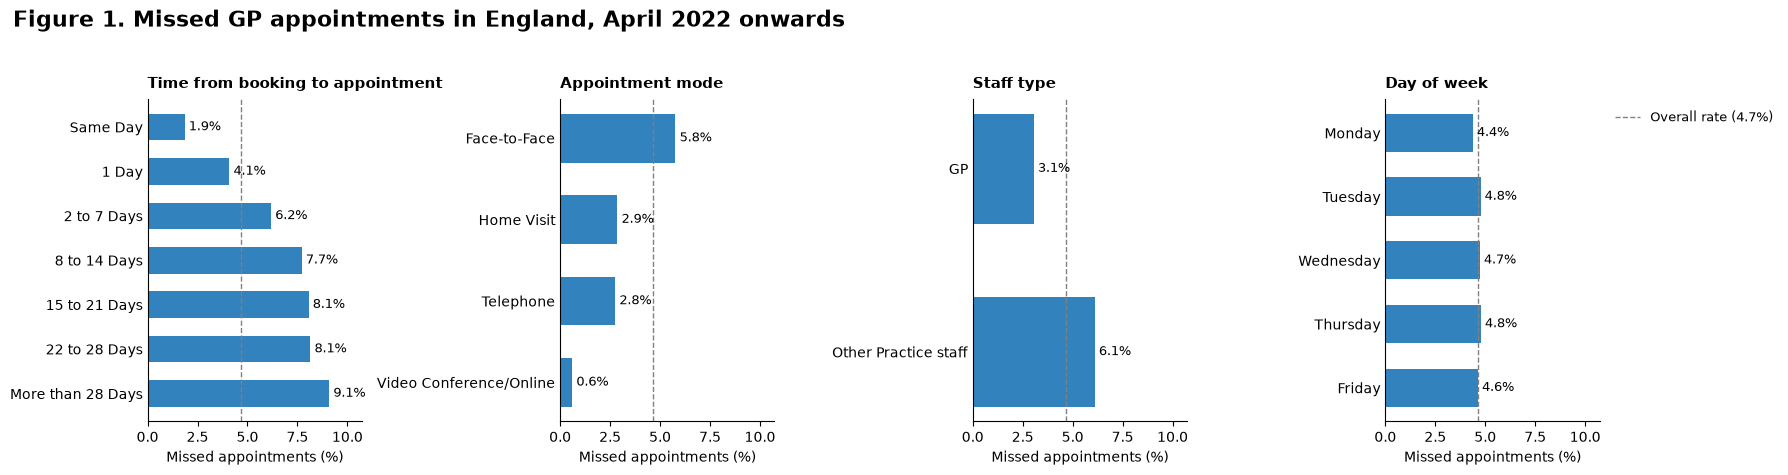

In [257]:
titles = {"lead": "Time from booking to appointment", "mode": "Appointment mode",
          "staff": "Staff type", "weekday": "Day of week"}
overall = 100 * d / n

fig, axes = plt.subplots(1, 4, figsize=(18, 4.8), sharex=True)
for ax, (g, t) in zip(axes, rate_tables.items()):
    t = t.iloc[::-1]                                  # first category at the top
    bars = ax.barh(t.index.astype(str), t["DNA %"], color="#3182bd", height=0.6)
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
    ax.axvline(overall, ls="--", color="grey", lw=1, label=f"Overall rate ({overall:.1f}%)")
    ax.set_title(titles[g], fontsize=11, pad=8)       # small gap above each panel
    ax.set_xlabel("Missed appointments (%)")
    ax.tick_params(axis="y", length=0)

axes[0].set_xlim(0, max(t["DNA %"].max() for t in rate_tables.values()) * 1.18)
axes[-1].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)

fig.suptitle("Figure 1. Missed GP appointments in England, April 2022 onwards",
             x=0.01, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.95])               # less space under the main title
fig.savefig("results/fig1_dna_rates.png")
plt.show()

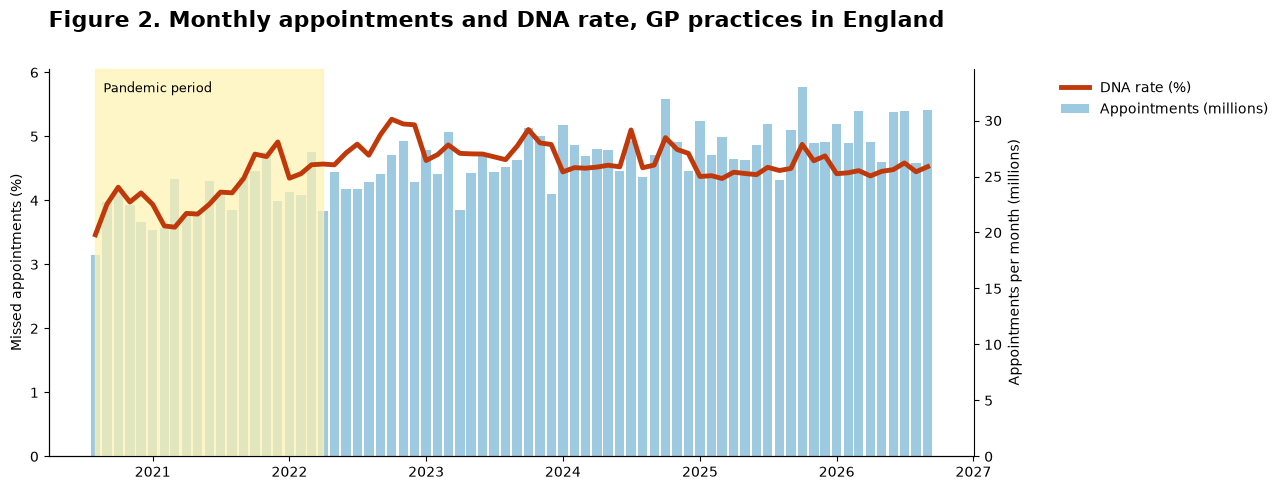

In [268]:
m = dna_rates("month", agg)
LINE = "#c0390b"      # dark orange-red for the DNA rate
BARS = "#9ecae1"      # light blue for appointments

fig, ax_rate = plt.subplots(figsize=(13, 5), facecolor="white")
ax_n = ax_rate.twinx()                      # second y-axis for appointments
ax_n.spines["right"].set_visible(True)
# Bars: appointments per month (millions), right-hand axis
ax_n.bar(m.index, m["total"] / 1e6, width=25, color=BARS, label="Appointments (millions)")
ax_n.set_ylabel("Appointments per month (millions)", color="black")
ax_n.tick_params(axis="y", colors="black")
ax_n.spines[["top"]].set_visible(False)

# Line: DNA rate, left-hand axis, drawn in front of the bars
ax_rate.plot(m.index, m["DNA %"], color=LINE, lw=3.5, label="DNA rate (%)")
ax_rate.set_zorder(ax_n.get_zorder() + 1)
ax_rate.patch.set_visible(False)
ax_rate.set_ylabel("Missed appointments (%)", color="black")
ax_rate.tick_params(axis="both", colors="black")
ax_rate.set_ylim(0, m["DNA %"].max() * 1.15)
ax_rate.spines[["top"]].set_visible(False)

# Pandemic period shading
ax_rate.axvspan(m.index.min(), pd.Timestamp("2022-03-31"), color="#fff3b0", alpha=0.7, zorder=0)
ax_rate.text(m.index.min(), m["DNA %"].max() * 1.08, "  Pandemic period",
             fontsize=9, color="black")

# One legend for both, outside on the right
h1, l1 = ax_rate.get_legend_handles_labels()
h2, l2 = ax_n.get_legend_handles_labels()
ax_rate.legend(h1 + h2, l1 + l2, frameon=False, labelcolor="black",
               loc="upper left", bbox_to_anchor=(1.08, 1))

ax_rate.set_title("Figure 2. Monthly appointments and DNA rate, GP practices in England",
                  fontsize=16, fontweight="bold", loc="left", pad=30, color="black")
fig.tight_layout()
fig.savefig("results/fig2_monthly_dna_rate.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

### Step 5 results

From April 2022 onwards, **1.47 billion appointments** were analysed. Overall, **4.66%** were missed (95% CI 4.65–4.66%), about 1 in 21 appointments.

- **Booking lead time (Table 1):** the strongest pattern. The DNA rate rose steadily with the time between booking and appointment, from **1.85%** for same-day appointments to **9.09%** for appointments booked more than 28 days ahead, about **five times higher**.
- **Appointment mode (Table 2):** face-to-face appointments had the highest DNA rate (**5.77%**), compared with **2.76%** for telephone and **0.60%** for video/online appointments.
- **Staff type (Table 3):** appointments with other practice staff (e.g. nurses) were missed about **twice as often** as GP appointments (**6.10% vs 3.05%**).
- **Day of week (Table 4):** differences were small, from **4.38%** on Mondays to **4.78%** on Thursdays.

Because the dataset is so large, all confidence intervals are very narrow, so even small differences are statistically significant. The **size** of the differences is what matters: lead time, mode and staff type show large differences, while day of week shows only small ones.

These are **unadjusted** rates. The factors are related to each other: for example, face-to-face appointments may be booked further ahead than telephone appointments. Step 6 uses logistic regression to estimate the effect of each factor while accounting for the others.

## Step 6. Logistic regression: which factors are linked to missed appointments?

**Why logistic regression:** the outcome is yes/no (missed or attended). The model estimates the effect of each factor **while holding the others constant**, as an **odds ratio (OR)**:
- OR > 1: higher odds of a missed appointment
- OR < 1: lower odds

Missed appointments are uncommon (about 5%), so an OR is close to a relative risk: an OR of 2 means roughly twice as likely to be missed.

**Grouped counts:** the outcome is written as `dna + attended`, so each row means "this many missed out of this many appointments". Every appointment is used without creating billions of rows.

**Cluster-robust standard errors by area:** appointments in the same area share local conditions, so they are not independent. Clustering by area gives honest confidence intervals.

**Unadjusted vs adjusted:** comparing each factor on its own with all factors together shows **confounding**. When an OR changes a lot after adjustment, part of the raw difference was explained by the other factors.

Data: April 2022 onwards, combined over months (the model has no time terms, so this gives the same results and runs faster). Reference groups: same-day booking, face-to-face, GP, Wednesday.

In [259]:
REF = {"lead": "Same Day", "mode": "Face-to-Face", "staff": "GP", "weekday": "Wednesday"}
TERMS = {g: f'C({g}, Treatment("{r}"))' for g, r in REF.items()}
RHS = " + ".join(TERMS.values())

# Combine over months: same answers, much smaller table
m6 = (recent.groupby(["area", "lead", "mode", "staff", "weekday"], observed=True)
            [["dna", "attended", "total"]].sum().reset_index())
m6 = m6[m6["total"] > 0].copy()
m6["lead"] = m6["lead"].astype(str)

def fit(rhs, data, cluster=True):
    """Binomial logistic regression on grouped counts (dna out of dna + attended)."""
    model = smf.glm(f"dna + attended ~ {rhs}", data=data, family=sm.families.Binomial())
    if cluster:
        return model.fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(data["area"])[0]})
    return model.fit()

def or_table(res):
    """Odds ratios with 95% confidence intervals."""
    ci = res.conf_int()
    t = pd.DataFrame({"OR": np.exp(res.params), "CI low": np.exp(ci[0]),
                      "CI high": np.exp(ci[1]), "p": res.pvalues})
    return t.drop(index="Intercept")

def nice(label):
   """'C(lead, Treatment("Same Day"))[T.1 Day]' -> 'Booked: 1 Day'"""
   if "[T." not in label:
       return label
   variable = label[2:label.index(",")]             # e.g. 'lead'
   level = label.split("[T.", 1)[1].rstrip("]")     # e.g. '1 Day'
   names = {"lead": "Booked", "mode": "Mode", "staff": "Staff", "weekday": "Day"}
   return f"{names.get(variable, variable)}: {level}"

def in_order(t):
    """Sort rows so lead times and weekdays appear in natural order."""
    days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
    def key(label):
        for i, l in enumerate(LEAD_ORDER):
            if f"[T.{l}]" in label:
                return (0, i, "")
        for i, l in enumerate(days):
            if f"[T.{l}]" in label:
                return (2, i, "")
        return (1, 0, label)
    return t.loc[sorted(t.index, key=key)]

unadj = pd.concat([or_table(fit(t, m6)) for t in TERMS.values()])
model6 = fit(RHS, m6)
adj = in_order(or_table(model6))

results6 = pd.DataFrame({
    "OR unadjusted": unadj["OR"].reindex(adj.index).values,
    "OR adjusted": adj["OR"].values,
    "95% CI": [f"{a:.2f}–{b:.2f}" for a, b in zip(adj["CI low"], adj["CI high"])],
}, index=[nice(i) for i in adj.index])
results6["Change after adjustment %"] = 100 * (results6["OR adjusted"] / results6["OR unadjusted"] - 1)
results6.to_csv("results/step6_odds_ratios.csv")

show_table(results6, "Table 5. Odds ratios for a missed appointment (April 2022 onwards)",
           {"OR unadjusted": "{:.2f}", "OR adjusted": "{:.2f}",
            "Change after adjustment %": "{:+.1f}"},
           bold_cols=["OR adjusted", "95% CI"])

,OR unadjusted,OR adjusted,95% CI,Change after adjustment %
Booked: 1 Day,2.26,2.01,1.92–2.11,-11.0
Booked: 2 to 7 Days,3.49,2.86,2.69–3.04,-17.9
Booked: 8 to 14 Days,4.42,3.44,3.21–3.68,-22.3
Booked: 15 to 21 Days,4.64,3.55,3.31–3.81,-23.5
Booked: 22 to 28 Days,4.69,3.56,3.31–3.83,-24.1
Booked: More than 28 Days,5.29,3.89,3.58–4.21,-26.6
Mode: Home Visit,0.48,0.64,0.58–0.71,+33.7
Mode: Telephone,0.46,0.63,0.58–0.70,+36.9
Mode: Video Conference/Online,0.10,0.17,0.13–0.22,+74.7
Staff: Other Practice staff,2.06,1.45,1.41–1.49,-29.7


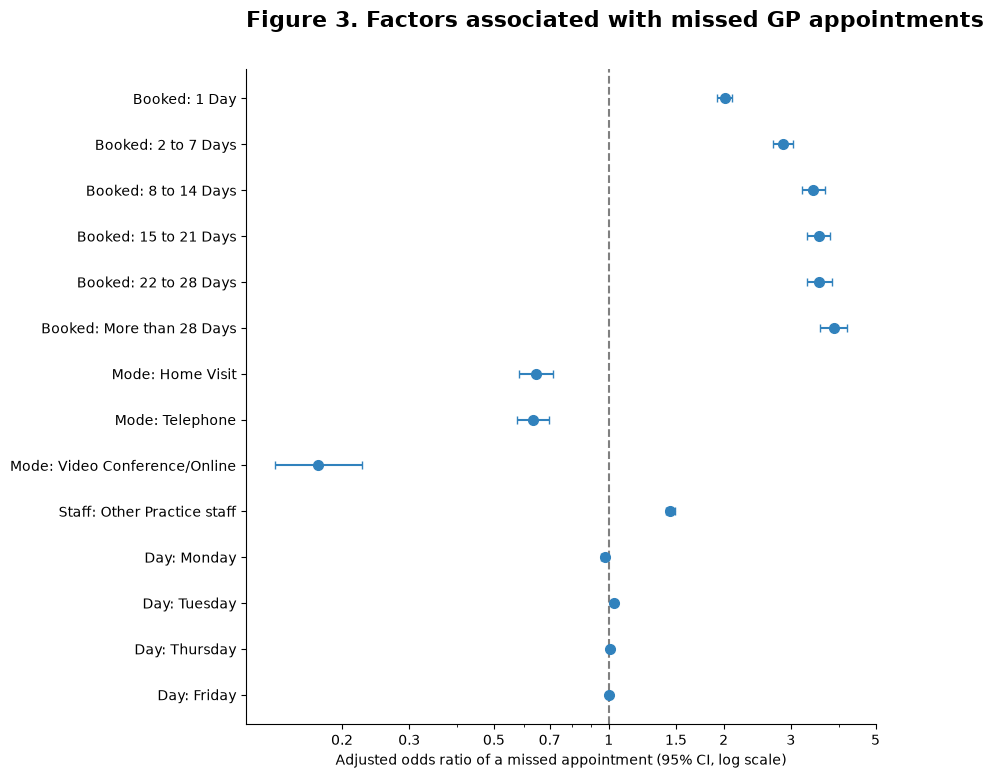

In [260]:
p = adj.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 0.42 * len(p) + 2))
ax.errorbar(p["OR"], range(len(p)), xerr=[p["OR"] - p["CI low"], p["CI high"] - p["OR"]],
            fmt="o", capsize=3, color="#3182bd", markersize=7)
ax.axvline(1, ls="--", color="grey")
ax.set_yticks(range(len(p)))
ax.set_yticklabels([nice(i) for i in p.index])
ax.set_xscale("log")
ticks = [t for t in [0.1, 0.2, 0.3, 0.5, 0.7, 1, 1.5, 2, 3, 5, 7, 10]
         if p["CI low"].min() * 0.8 <= t <= p["CI high"].max() * 1.25]
ax.set_xticks(ticks)
ax.set_xticklabels([f"{t:g}" for t in ticks])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("Adjusted odds ratio of a missed appointment (95% CI, log scale)")
ax.set_title("Figure 3. Factors associated with missed GP appointments")
fig.tight_layout()
fig.savefig("results/fig3_forest_plot.png")
plt.show()

### Step 6 results

Compared with the reference groups (same-day booking, face-to-face, GP, Wednesday), after adjusting for all other factors:

- **Booking lead time was the strongest factor.** The odds of a missed appointment rose steadily with the time between booking and appointment: **2.0 times** for next-day bookings (OR 2.01, 95% CI 1.92–2.11) up to **3.9 times** for bookings more than 28 days ahead (OR 3.89, 3.58–4.21).
- **Remote appointments were missed less often.** Compared with face-to-face, the odds were **37% lower** for telephone (OR 0.63, 0.58–0.70), **36% lower** for home visits (OR 0.64, 0.58–0.71) and **83% lower** for video/online appointments (OR 0.17, 0.13–0.22).
- **Appointments with other practice staff** (e.g. nurses) had **45% higher odds** of being missed than GP appointments (OR 1.45, 1.41–1.49).
- **Day of the week made almost no difference** (ORs 0.97–1.03).

**Confounding.** Adjustment changed several odds ratios noticeably:
- The effect of **staff type** fell from OR 2.06 to 1.45. About a third of the raw difference was explained by other factors: appointments with other practice staff are more often booked in advance and held face-to-face.
- The lower odds for **remote appointments** moved closer to 1 after adjustment (e.g. telephone from 0.46 to 0.63), because remote appointments are more often booked for the same day.
- The **lead-time** effects fell by 11–27% but remained large, so booking far in advance is linked to missed appointments in its own right.

These are associations in observational data, not proof of cause. Missed appointments are fairly uncommon, so the odds ratios are roughly comparable to relative risks, although they somewhat overstate them for the groups with the highest rates.

## Step 7. Model checks

**7a. Overdispersion.** The binomial model assumes a certain amount of variation. Dividing the Pearson chi-square by its degrees of freedom checks this: about 1 is fine; well above 1 means more variation than the model expects (usually because areas differ), so standard confidence intervals would be too narrow.

Three ways of calculating the confidence intervals are compared:
- **standard** (assumes no overdispersion)
- **quasi-binomial** (widens intervals by the amount of overdispersion)
- **cluster-robust by area** (used in Step 6)

The odds ratios are the same in all three; only their uncertainty changes.

In [261]:
plain = fit(RHS, m6, cluster=False)
dispersion = plain.pearson_chi2 / plain.df_resid
print(f"Dispersion (Pearson chi-square / df): {dispersion:.1f}   (about 1 = no overdispersion)")

# Quasi-binomial: same odds ratios, standard errors multiplied by sqrt(dispersion)
quasi = smf.glm(f"dna + attended ~ {RHS}", data=m6,
                family=sm.families.Binomial()).fit(scale=dispersion)

def ci_width(res):
    t = in_order(or_table(res))
    return (t["CI high"] - t["CI low"]).values

widths = pd.DataFrame({
    "Standard": ci_width(plain),
    "Quasi-binomial": ci_width(quasi),
    "Cluster-robust (used)": (adj["CI high"] - adj["CI low"]).values,
}, index=[nice(i) for i in adj.index])
widths.to_csv("results/step7_ci_widths.csv")

show_table(widths, "Table 6. Width of 95% confidence intervals under three approaches",
           {c: "{:.4f}" for c in widths.columns}, bold_cols=["Cluster-robust (used)"])

Dispersion (Pearson chi-square / df): 454.6   (about 1 = no overdispersion)


,Standard,Quasi-binomial,Cluster-robust (used)
Booked: 1 Day,0.0044,0.0943,0.1913
Booked: 2 to 7 Days,0.0044,0.0940,0.3547
Booked: 8 to 14 Days,0.0055,0.1177,0.4730
Booked: 15 to 21 Days,0.0065,0.1389,0.4994
Booked: 22 to 28 Days,0.0075,0.1590,0.5238
Booked: More than 28 Days,0.0080,0.1712,0.6277
Mode: Home Visit,0.0041,0.0876,0.1338
Mode: Telephone,0.0009,0.0183,0.1206
Mode: Video Conference/Online,0.0010,0.0212,0.0918
Staff: Other Practice staff,0.0016,0.0338,0.0752


### Step 7a results

The dispersion was **454.6**, far above 1. There is much more variation between rows than a simple binomial model assumes. This is expected with routinely collected data aggregated by area: each row contains many appointments, and areas differ in ways the model does not include (e.g. population, deprivation, reminder systems).

Table 6 shows why this matters:
- **Standard confidence intervals were far too narrow**, e.g. a width of 0.004 for next-day booking compared with 0.19 with cluster-robust errors. Ignoring overdispersion would make the results look far more certain than they are.
- **Cluster-robust intervals (used in Step 6) were the widest** for lead time and mode, suggesting that the size of these effects **varies between areas**.
- For **day of the week**, quasi-binomial intervals were wider than cluster-robust ones, suggesting the small weekday effects are similar across areas.

Even with the most cautious intervals, the main findings (lead time, mode and staff type) remain clearly different from 1, so the conclusions do not depend on the method used.

**7b. Sensitivity analyses.** Do the main results hold if the data are changed in reasonable ways?

1. **Excluding areas with implausible DNA rates** (below 1% or above 15%), which may reflect recording problems.
2. **The pandemic period instead** (to March 2022), to see whether the same factors mattered then.

If the odds ratios are similar to the main model, the conclusions are **robust**.

In [262]:
# 1. Exclude areas with implausible DNA rates
ar = m6.groupby("area")[["dna", "total"]].sum()
ar["rate"] = ar["dna"] / ar["total"]
ok_areas = ar[(ar["rate"] >= 0.01) & (ar["rate"] <= 0.15)].index
print(f"Areas excluded for implausible DNA rates: {len(ar) - len(ok_areas)} of {len(ar)}")
sens1 = or_table(fit(RHS, m6[m6["area"].isin(ok_areas)]))

# 2. Pandemic period
pand = (agg[agg["period"] != "After Mar 2022"]
        .groupby(["area", "lead", "mode", "staff", "weekday"], observed=True)
        [["dna", "attended", "total"]].sum().reset_index())
pand = pand[pand["total"] > 0].copy()
pand["lead"] = pand["lead"].astype(str)
sens2 = or_table(fit(RHS, pand))

sens = pd.DataFrame({
    "Main model": adj["OR"].values,
    "Excl. implausible areas": sens1["OR"].reindex(adj.index).values,
    "Pandemic period": sens2["OR"].reindex(adj.index).values,
}, index=[nice(i) for i in adj.index])
sens.to_csv("results/step7_sensitivity.csv")

show_table(sens, "Table 7. Sensitivity analyses: adjusted odds ratios",
           {c: "{:.2f}" for c in sens.columns}, bold_cols=["Main model"])

Areas excluded for implausible DNA rates: 0 of 107


,Main model,Excl. implausible areas,Pandemic period
Booked: 1 Day,2.01,2.01,1.89
Booked: 2 to 7 Days,2.86,2.86,2.61
Booked: 8 to 14 Days,3.44,3.44,3.14
Booked: 15 to 21 Days,3.55,3.55,3.41
Booked: 22 to 28 Days,3.56,3.56,3.52
Booked: More than 28 Days,3.89,3.89,4.23
Mode: Home Visit,0.64,0.64,0.82
Mode: Telephone,0.63,0.63,0.54
Mode: Video Conference/Online,0.17,0.17,0.82
Staff: Other Practice staff,1.45,1.45,1.76


### Step 7b results

**Implausible areas:** all 107 areas had overall DNA rates between 1% and 15%, so no area was excluded and the results were unchanged. This suggests no area had obviously implausible recording of missed appointments.

**Pandemic period (to March 2022):**
- **Booking lead time** had a very similar effect during the pandemic (e.g. OR 4.23 vs 3.89 for more than 28 days ahead). The link between booking far in advance and missed appointments is **consistent over time**.
- **Telephone appointments** had a slightly stronger protective effect during the pandemic (OR 0.54 vs 0.63).
- **Video/online appointments** were much less protective during the pandemic (OR 0.82 vs 0.17 afterwards). Video consultations were new and less established in general practice at the time, so their role may have changed as they became routine.
- **Appointments with other practice staff** had a stronger association with missed appointments during the pandemic (OR 1.76 vs 1.45).
- **Day of the week** remained unimportant.

**Conclusion:** the main finding, that appointments booked further ahead are much more likely to be missed, held in both periods. The effects of appointment mode changed after the pandemic, so the main analysis uses April 2022 onwards to reflect current practice.

## Step 8. Trend over time and seasonality

Two questions, using April 2022 onwards:

1. **Trend:** after adjusting for appointment type, is the DNA rate rising or falling? Time is measured in **years since April 2022**, so its odds ratio is the **change in odds per year**.
2. **Seasonality:** which months have more missed appointments? Each month is compared with **January**.

The model adjusts for lead time, mode and staff type, with standard errors clustered by area.

In [263]:
import calendar

# One row per area x month x lead time x mode x staff type
m8 = (recent.groupby(["area", "month", "month_of_year", "lead", "mode", "staff"], observed=True)
            [["dna", "attended", "total"]].sum().reset_index())
m8 = m8[m8["total"] > 0].copy()
m8["lead"] = m8["lead"].astype(str)
m8["years"] = (m8["month"] - pd.Timestamp("2022-04-01")).dt.days / 365.25

rhs8 = ("years + C(month_of_year, Treatment(1)) + "
        + " + ".join(TERMS[g] for g in ["lead", "mode", "staff"]))
model8 = fit(rhs8, m8)
t8 = or_table(model8)

# Trend
trend = t8.loc["years"]
print(f"Change in odds of a missed appointment per year: OR {trend['OR']:.3f} "
      f"(95% CI {trend['CI low']:.3f}–{trend['CI high']:.3f})")

# Seasonality: month odds ratios vs January
season = t8[t8.index.str.startswith("C(month_of_year")].copy()
season.index = [int(i.split("[T.")[1].rstrip("]")) for i in season.index]
season.loc[1] = [1.0, 1.0, 1.0, np.nan]                        # January = reference
season = season.sort_index()
season.index = [calendar.month_abbr[m] for m in season.index]  # 1 -> 'Jan', 12 -> 'Dec'
season.to_csv("results/step8_seasonality.csv")

season_show = pd.DataFrame({
    "OR vs January": season["OR"],
    "95% CI": [f"{a:.2f}–{b:.2f}" for a, b in zip(season["CI low"], season["CI high"])],
})
show_table(season_show, "Table 8. Seasonal pattern: adjusted odds ratio by month (vs January)",
           {"OR vs January": "{:.2f}"}, bold_cols=["OR vs January"])

Change in odds of a missed appointment per year: OR 0.988 (95% CI 0.982–0.994)


,OR vs January,95% CI
Jan,1.00,1.00–1.00
Feb,1.00,0.99–1.00
Mar,1.01,1.01–1.02
Apr,1.00,1.00–1.01
May,1.01,1.00–1.01
Jun,1.01,1.01–1.02
Jul,1.06,1.05–1.06
Aug,1.01,1.01–1.01
Sep,1.03,1.03–1.04
Oct,1.06,1.04–1.07


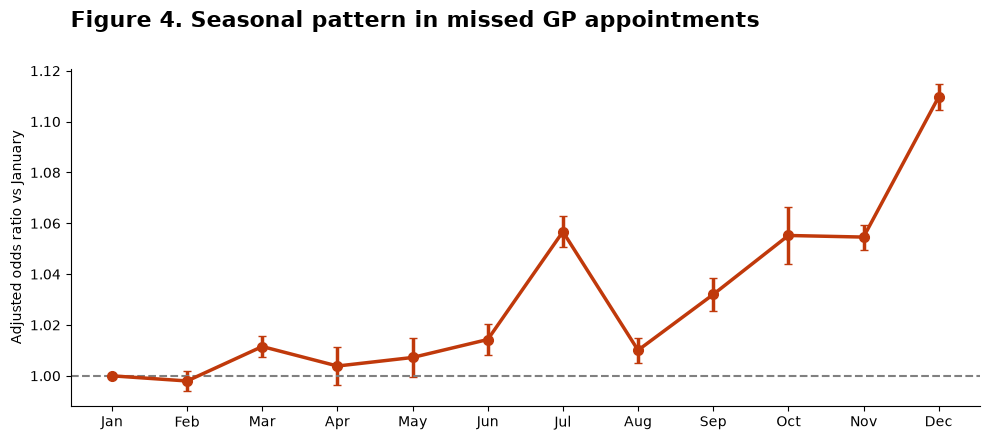

In [264]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = range(len(season))
ax.errorbar(x, season["OR"],
            yerr=[season["OR"] - season["CI low"], season["CI high"] - season["OR"]],
            fmt="o-", capsize=3, color="#c0390b", lw=2.5, markersize=7)
ax.axhline(1, ls="--", color="grey")
ax.set_xticks(list(x))
ax.set_xticklabels(season.index)
ax.set_ylabel("Adjusted odds ratio vs January")
ax.set_title("Figure 4. Seasonal pattern in missed GP appointments")
fig.tight_layout()
fig.savefig("results/fig4_seasonality.png")
plt.show()

### Step 8 results

**Trend:** after adjusting for lead time, mode and staff type, the odds of a missed appointment **fell slightly, by 1.2% per year** (OR 0.988 per year, 95% CI 0.982–0.994) between April 2022 and September 2026.

**Seasonality (Table 8, Figure 4):** compared with January, missed appointments were most common in:
- **December**: 11% higher odds (OR 1.11, 95% CI 1.10–1.11), possibly reflecting winter illness and the Christmas period
- **July**: 6% higher (OR 1.06), around the start of the school summer holidays
- **October and November**: 5–6% higher

February to June were similar to January.

The monthly chart (Figure 2) suggested peaks each autumn. After adjusting for booking lead time, the October effect is smaller, which suggests that part of the autumn peak comes from appointments booked well in advance (for example, seasonal vaccination clinics).

Seasonal effects were **modest compared with booking lead time** (OR up to 3.9), so when an appointment is booked matters much more than the month it falls in.

## Step 9. Compare areas fairly: standardisation and funnel plot

Comparing raw DNA rates between areas is unfair: an area that books many appointments weeks ahead will have more missed appointments for that reason alone.

1. **Case-mix model:** a logistic model with every factor **except area** predicts how many DNAs each area would be **expected** to have, given its mix of appointments.
2. **Standardised DNA ratio** = observed ÷ expected. A ratio of 1.2 means 20% more missed appointments than expected.
3. **Funnel plot:** each area's ratio is plotted against its size. Control limits are wider for small areas, whose rates are noisier. Because of the large overdispersion found in Step 7, the limits are widened accordingly (Spiegelhalter, 2005), so only genuinely unusual areas fall outside.

**The last 12 months** are used, so each area appears once under its current code (area codes and boundaries changed during 2020–2026).

Funnel plots are the standard way health agencies, including NSW Health and the Bureau of Health Information, compare hospitals and districts fairly.

In [265]:
# Last 12 months
last12_start = agg["month"].max() - pd.DateOffset(months=11)
m9 = (agg[agg["month"] >= last12_start]
      .groupby(["area", "lead", "mode", "staff", "weekday"], observed=True)
      [["dna", "attended", "total"]].sum().reset_index())
m9 = m9[m9["total"] > 0].copy()
m9["lead"] = m9["lead"].astype(str)
print(f"Period: {last12_start:%b %Y} to {agg['month'].max():%b %Y}")

# Expected DNAs from a case-mix model without area
casemix = fit(RHS, m9, cluster=False)
m9["expected"] = casemix.predict(m9) * m9["total"]

area = m9.groupby("area").agg(observed=("dna", "sum"), expected=("expected", "sum"),
                              total=("total", "sum")).reset_index()
area["crude DNA %"] = 100 * area["observed"] / area["total"]
area["ratio"] = area["observed"] / area["expected"]

# Overdispersion-adjusted 99.8% limits
area["z"] = (area["observed"] - area["expected"]) / np.sqrt(area["expected"])
phi = max(1.0, float((area["z"] ** 2).mean()))
lim = 3.09 * np.sqrt(phi / area["expected"])
area["flag"] = np.select([area["ratio"] > 1 + lim, area["ratio"] < 1 - lim],
                         ["Higher than expected", "Lower than expected"],
                         "Within expected range")

# Area names (most recent name for each code)
names = (combined[combined["date"] >= last12_start][[AREA, "SUB_ICB_LOCATION_NAME"]]
         .drop_duplicates().astype(str)
         .drop_duplicates(AREA, keep="last")
         .rename(columns={AREA: "area", "SUB_ICB_LOCATION_NAME": "name"}))
area = area.merge(names, on="area", how="left").sort_values("ratio", ascending=False)
area.to_csv("results/step9_area_ratios.csv", index=False)

print(f"Areas: {len(area)};  overdispersion factor phi = {phi:.1f}")
display(area["flag"].value_counts().to_frame("Number of areas"))

top = (area.set_index("name")[["total", "crude DNA %", "ratio", "flag"]]
           .rename(columns={"total": "Appointments", "ratio": "Observed / expected", "flag": "Result"}))
top.index.name = None
show_table(top.head(10), "Table 9. Ten areas with the highest standardised DNA ratio (last 12 months)",
           {"Appointments": "{:,.0f}", "crude DNA %": "{:.2f}", "Observed / expected": "{:.2f}"},
           bold_cols=["Observed / expected"])

Period: Oct 2025 to Sep 2026
Areas: 106;  overdispersion factor phi = 12385.5


,Number of areas
flag,
Within expected range,105
Higher than expected,1


,Appointments,crude DNA %,Observed / expected,Result
NHS Greater Manchester ICB - 14L,"3,372,746",7.66,1.80,Within expected range
NHS Cheshire and Merseyside ICB - 99A,"3,001,357",6.27,1.68,Within expected range
NHS North East London ICB - A3A8R,"12,013,977",6.99,1.65,Higher than expected
NHS South East London ICB - 72Q,"8,836,345",6.56,1.53,Within expected range
NHS Lancashire and South Cumbria ICB - 00Q,"920,024",6.79,1.50,Within expected range
NHS Greater Manchester ICB - 01G,"1,625,039",6.63,1.50,Within expected range
NHS Cheshire and Merseyside ICB - 01J,"973,935",6.67,1.48,Within expected range
NHS Birmingham and Solihull ICB - 15E,"9,347,181",6.08,1.48,Within expected range
NHS West and North London ICB - 93C,"8,514,327",5.46,1.45,Within expected range
NHS Thames Valley ICB - U2G6B,"2,347,341",6.18,1.42,Within expected range


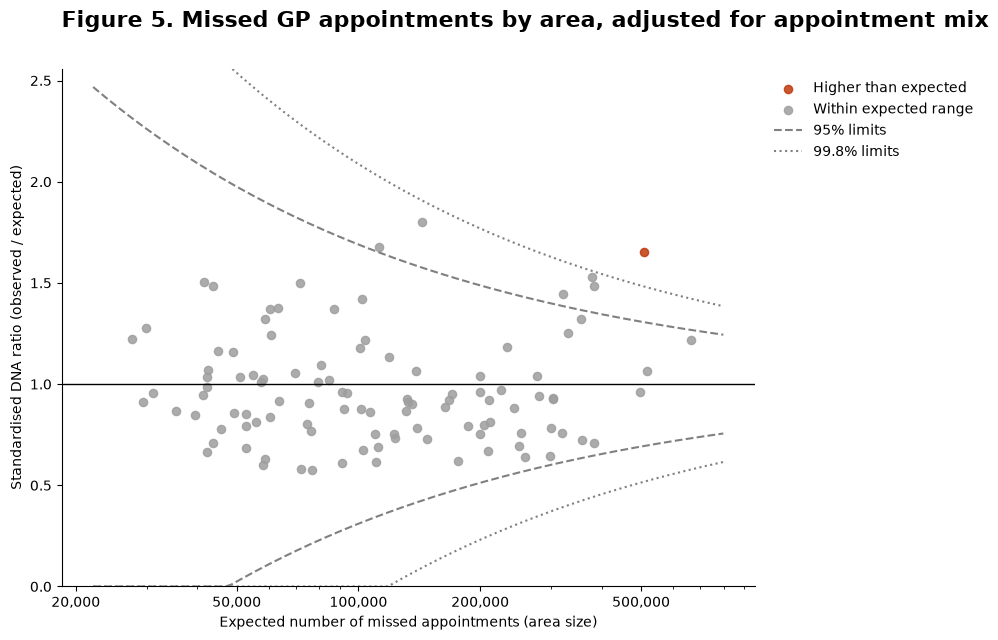

In [266]:
E = np.linspace(area["expected"].min() * 0.8, area["expected"].max() * 1.2, 500)
colours = {"Higher than expected": "#c0390b", "Lower than expected": "#3182bd",
           "Within expected range": "#9e9e9e"}

fig, ax = plt.subplots(figsize=(10, 6.5))

# Dots: one per area
for flag, g in area.groupby("flag"):
    ax.scatter(g["expected"], g["ratio"], s=35, alpha=0.85, color=colours[flag], label=flag)

# Reference line at 1 (= as expected)
ax.axhline(1, color="black", lw=1)

# Funnel limits (lower limits stop at 0)
for z, style, lab in [(1.96, "--", "95% limits"), (3.09, ":", "99.8% limits")]:
    ax.plot(E, 1 + z * np.sqrt(phi / E), style, color="grey", label=lab)
    ax.plot(E, np.clip(1 - z * np.sqrt(phi / E), 0, None), style, color="grey")

# x-axis: log scale with readable numbers
ax.set_xscale("log")
ax.xaxis.set_major_locator(plt.matplotlib.ticker.LogLocator(subs=[1, 2, 5]))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.xaxis.set_minor_formatter(plt.NullFormatter())

# y-axis: from 0 to halfway between the highest dot and the top of the funnel
top_dot = area["ratio"].max()
top_funnel = (1 + 3.09 * np.sqrt(phi / E)).max()
ax.set_ylim(0, (top_dot + top_funnel) / 2)

# Labels, title, legend
ax.set_xlabel("Expected number of missed appointments (area size)")
ax.set_ylabel("Standardised DNA ratio (observed / expected)")
ax.set_title("Figure 5. Missed GP appointments by area, adjusted for appointment mix")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))

fig.tight_layout()
fig.savefig("results/fig5_funnel_plot.png")
plt.show()

### Step 9 results

Over the last 12 months (October 2025 – September 2026), 106 areas were compared after adjusting for each area's mix of appointments (lead time, mode, staff type and weekday).

- **105 of 106 areas** had DNA rates consistent with chance variation: their standardised ratios fell inside the funnel limits.
- **One area had more missed appointments than expected:** **NHS North East London ICB (A3A8R)**, with **65% more missed appointments than expected** for its appointment mix (observed/expected ratio 1.65; crude DNA rate 6.99%, from 12.0 million appointments).
- **No area was significantly lower than expected.**

**Why size matters:** NHS Greater Manchester ICB (14L) had a higher ratio (1.80) but is **within** the expected range, because it is much smaller (3.4 million appointments) and its rate is less precise. North East London's result is flagged because its very large size makes the estimate precise. This is exactly what a funnel plot is designed to show: a ratio must be judged together with its precision.

**Overdispersion:** the variation between areas was very large (overdispersion factor φ = 12,386), meaning areas differ in many ways the model does not capture (e.g. deprivation, population, local booking systems). The funnel limits were widened accordingly, so only genuinely unusual areas are flagged. Several London and North West areas were close to the upper limit and could be monitored.

**How this could be used:** areas above the funnel could be prioritised for review of booking practices and reminder systems. Funnel plots are the standard way health agencies, including NSW Health and the Bureau of Health Information, compare hospitals and districts fairly.

## Step 10. Key results

This table collects the main numbers in one place, for the summary, README and resume.

In [267]:
key = adj.copy()
key.index = [nice(i) for i in key.index]

summary = pd.DataFrame({"Result": [
    f"{n:,}",
    f"{100*d/n:.2f}% (95% CI {100*lo:.2f}–{100*hi:.2f}%)",
    f"{key.loc['Booked: More than 28 Days','OR']:.2f} ({key.loc['Booked: More than 28 Days','CI low']:.2f}–{key.loc['Booked: More than 28 Days','CI high']:.2f})",
    f"{key.loc['Mode: Telephone','OR']:.2f} ({key.loc['Mode: Telephone','CI low']:.2f}–{key.loc['Mode: Telephone','CI high']:.2f})",
    f"{key.loc['Mode: Video Conference/Online','OR']:.2f} ({key.loc['Mode: Video Conference/Online','CI low']:.2f}–{key.loc['Mode: Video Conference/Online','CI high']:.2f})",
    f"{key.loc['Staff: Other Practice staff','OR']:.2f} ({key.loc['Staff: Other Practice staff','CI low']:.2f}–{key.loc['Staff: Other Practice staff','CI high']:.2f})",
    f"{trend['OR']:.3f} ({trend['CI low']:.3f}–{trend['CI high']:.3f})",
    f"{dispersion:.1f}",
    f"{(area['flag'] == 'Higher than expected').sum()} of {len(area)}",
]}, index=[
    "Appointments analysed (Apr 2022 onwards)",
    "Overall DNA rate",
    "OR: booked more than 28 days ahead (vs same day)",
    "OR: telephone (vs face-to-face)",
    "OR: video/online (vs face-to-face)",
    "OR: other practice staff (vs GP)",
    "OR: change per year (trend)",
    "Dispersion",
    "Areas higher than expected (last 12 months)",
])
summary.to_csv("results/step10_key_results.csv")
show_table(summary, "Table 10. Key results")

,Result
Appointments analysed (Apr 2022 onwards),"1,470,186,599"
Overall DNA rate,4.66% (95% CI 4.65–4.66%)
OR: booked more than 28 days ahead (vs same day),3.89 (3.58–4.21)
OR: telephone (vs face-to-face),0.63 (0.58–0.70)
OR: video/online (vs face-to-face),0.17 (0.13–0.22)
OR: other practice staff (vs GP),1.45 (1.41–1.49)
OR: change per year (trend),0.988 (0.982–0.994)
Dispersion,454.6
Areas higher than expected (last 12 months),1 of 106


## Conclusions

Using 1.47 billion routinely collected GP appointments in England (April 2022 – September 2026):

1. **About 1 in 21 appointments (4.66%) was missed.**
2. **Booking lead time was the strongest factor.** After adjustment, appointments booked more than 28 days ahead had almost **four times the odds** of being missed compared with same-day appointments. This held in both the pandemic and post-pandemic periods.
3. **Remote appointments were missed less often** than face-to-face ones: 37% lower odds for telephone and 83% lower for video/online.
4. **Appointments with other practice staff** had 45% higher odds of being missed than GP appointments, partly because they are more often booked in advance.
5. **Day of the week made almost no difference.**
6. **Trend:** after adjustment, the odds of a missed appointment fell slightly, by 1.2% per year (OR 0.988, 95% CI 0.982–0.994). Missed appointments were most common in December.
7. **Areas:** after adjusting for appointment mix, one area (NHS North East London ICB, A3A8R) had significantly more missed appointments than expected.

**Implications:** reminder systems could target appointments booked well in advance; offering remote appointments where clinically appropriate may reduce missed appointments; areas above the funnel limits could review their booking and reminder practices.

## Limitations

- **Aggregated data:** results describe patterns across appointments, not individual patients. Patient characteristics (age, deprivation, health conditions) were not available.
- **Unknown attendance status (5.2%)** was excluded; if these appointments differ from others, the DNA rate could be biased.
- **Recording practices vary** between GP practices and systems.
- **Association, not causation:** appointments booked far ahead may differ in type or urgency. A randomised trial of reminders would provide stronger evidence.
- **Area codes and boundaries changed** during 2020–2026, so area comparisons used the last 12 months only.
- **English data**, which may not transfer directly to Australian health services.

## Relevance to NSW

Missed appointments also affect NSW outpatient and community health services. The methods used here (rates with confidence intervals, adjusted logistic regression, handling overdispersion, and standardised comparisons using funnel plots) are standard tools for analysing routinely collected health data and comparing services fairly across Local Health Districts.